# 🔍 Notebook 02 — EDA, Data Audit & Leakage-Safe Split
**NB6057CEM CW1 | T1 (8 marks)**

Loads the EuroSAT arrays, runs a full data audit, produces required plots, and creates the stratified train/val/test split.

---

## Setup

In [31]:
import os, json, hashlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from google.colab import drive

drive.mount('/content/drive')

# Copy data from Drive to fast local Colab disk
!mkdir -p /content/data
!cp -r /content/drive/MyDrive/ann_cw1/eurosat /content/data/

os.makedirs('figures', exist_ok=True)
os.makedirs('splits', exist_ok=True)
print('Setup complete.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup complete.


## T1b Step 1: Load images & compute MD5 hashes

In [32]:
root = '/content/data/eurosat/2750'
classes = sorted(os.listdir(root))
paths, labels, hashes, bad = [], [], [], []

for i, c in enumerate(classes):
    for f in sorted(os.listdir(f'{root}/{c}')):
        p = f'{root}/{c}/{f}'
        try:
            Image.open(p).verify()   # corrupt-file check
        except Exception as e:
            bad.append(p)
            continue
        paths.append(p)
        labels.append(i)
        hashes.append(hashlib.md5(open(p, 'rb').read()).hexdigest())

print(f'Total valid images : {len(paths)}')
print(f'Corrupt/unreadable : {len(bad)}')

Total valid images : 27000
Corrupt/unreadable : 0


## T1b Step 2: Build numpy arrays (once — save to Drive)

In [33]:
y = np.array(labels)
X = np.stack([np.array(Image.open(p).convert('RGB')) for p in paths]).astype(np.uint8)
print(f'X shape: {X.shape}, y shape: {y.shape}')  # expect (27000, 64, 64, 3)
print(f'Pixel range: [{X.min()}, {X.max()}]')

# Save permanently to Google Drive
np.savez_compressed('/content/drive/MyDrive/ann_cw1/eurosat_64.npz', X=X, y=y)
print('Saved eurosat_64.npz to Drive.')

X shape: (27000, 64, 64, 3), y shape: (27000,)
Pixel range: [0, 255]
Saved eurosat_64.npz to Drive.


## T1b Step 3: Data Audit Report

In [34]:
# Duplicate check
dup_count = len(hashes) - len(set(hashes))

# Class balance
unique, counts = np.unique(y, return_counts=True)

print('=' * 50)
print('DATA AUDIT REPORT')
print('=' * 50)
print(f'Total images     : {len(X)}')
print(f'Corrupt files    : {len(bad)}')
print(f'Exact duplicates : {dup_count}  (hash-based; near-dupes not checked)')
print(f'Image shape      : {X.shape[1:]}  (all images should be 64x64x3)')
print(f'Pixel dtype      : {X.dtype}')
print(f'Pixel range      : [{X.min()}, {X.max()}]')
print()
print('Class counts:')
for ci, cnt in zip(unique, counts):
    print(f'  {classes[ci]:25s}: {cnt}')

DATA AUDIT REPORT
Total images     : 27000
Corrupt files    : 0
Exact duplicates : 0  (hash-based; near-dupes not checked)
Image shape      : (64, 64, 3)  (all images should be 64x64x3)
Pixel dtype      : uint8
Pixel range      : [0, 255]

Class counts:
  AnnualCrop               : 3000
  Forest                   : 3000
  HerbaceousVegetation     : 3000
  Highway                  : 2500
  Industrial               : 2500
  Pasture                  : 2000
  PermanentCrop            : 2500
  Residential              : 3000
  River                    : 2500
  SeaLake                  : 3000


## T1b Plot 1: Class Distribution Bar Chart

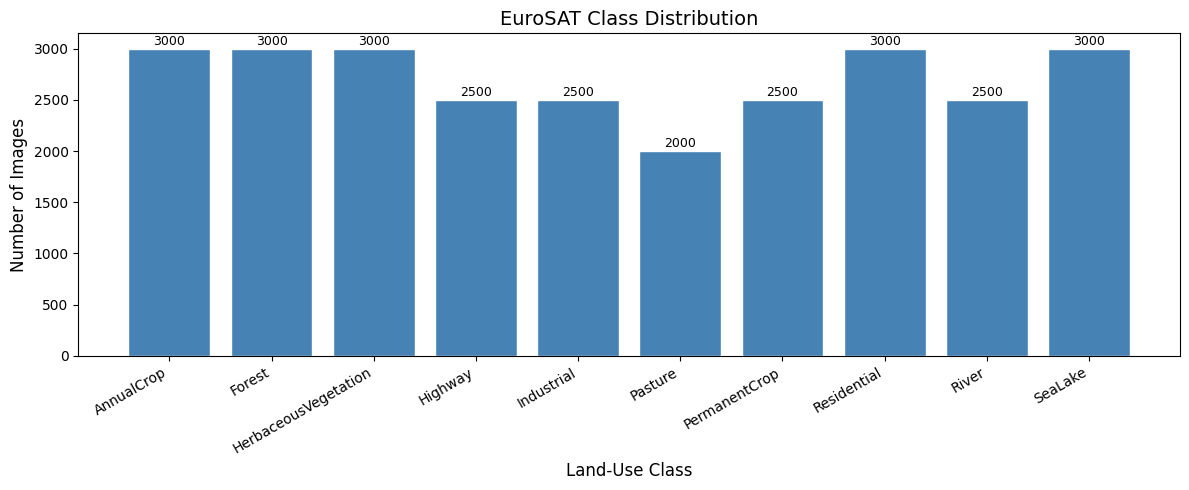

Saved: figures/class_distribution.png
Design note: Classes unequal in size -> use macro-F1 as primary metric.


In [35]:
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(classes, counts, color='steelblue', edgecolor='white')
ax.set_xlabel('Land-Use Class', fontsize=12)
ax.set_ylabel('Number of Images', fontsize=12)
ax.set_title('EuroSAT Class Distribution', fontsize=14)
plt.xticks(rotation=30, ha='right')
for bar, cnt in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10, str(cnt),
            ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig('figures/class_distribution.png', dpi=150)
plt.show()
print('Saved: figures/class_distribution.png')
print('Design note: Classes unequal in size -> use macro-F1 as primary metric.')

## T1b Plot 2: Sample Grid (3 images per class)

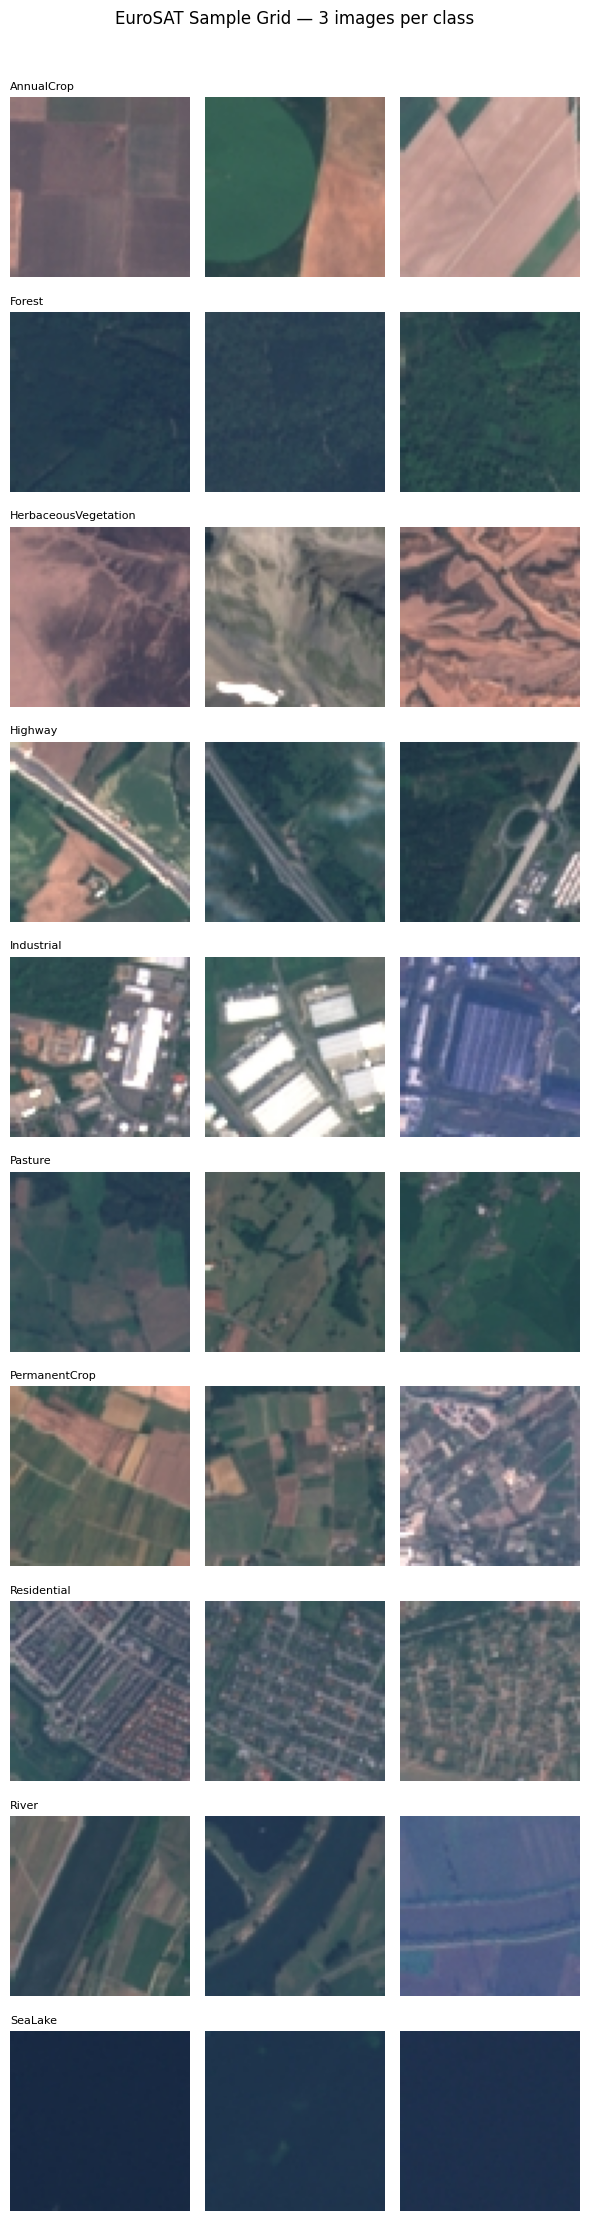

Saved: figures/sample_grid.png
Design note: Pasture vs Herbaceous and Highway vs Industrial look similar -> expect those confusions.


In [36]:
fig, axes = plt.subplots(10, 3, figsize=(6, 22))
for ci, cls in enumerate(classes):
    idx = np.where(y == ci)[0][:3]
    for j, ix in enumerate(idx):
        axes[ci, j].imshow(X[ix])
        axes[ci, j].axis('off')
        if j == 0:
            axes[ci, j].set_title(cls, fontsize=8, loc='left')
plt.suptitle('EuroSAT Sample Grid — 3 images per class', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig('figures/sample_grid.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/sample_grid.png')
print('Design note: Pasture vs Herbaceous and Highway vs Industrial look similar -> expect those confusions.')

## T1b Plot 3 (Optional): Mean Pixel Intensity per Channel

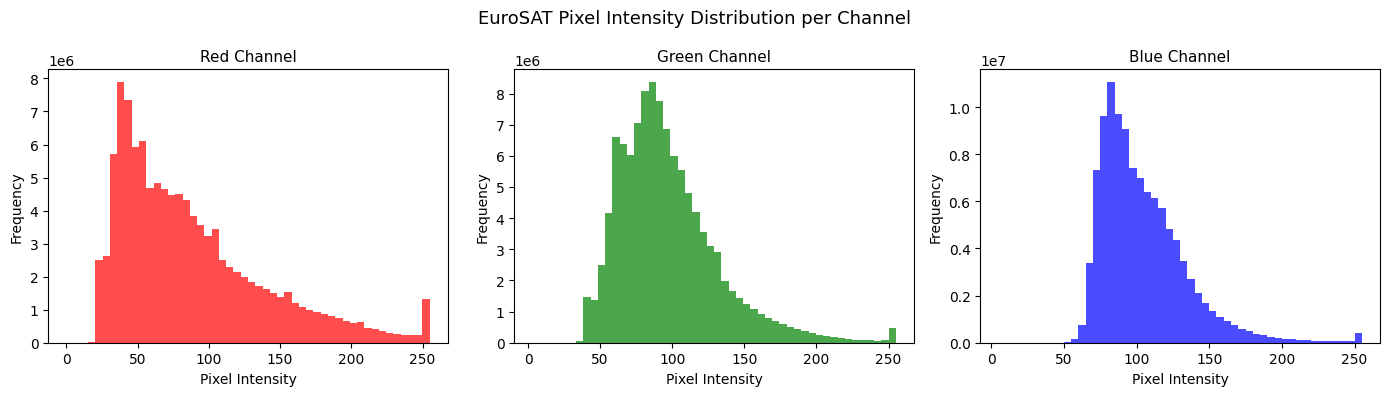

Saved: figures/pixel_histograms.png
Design note: Different channel means -> supports per-channel normalisation.


In [37]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
channel_names = ['Red', 'Green', 'Blue']
colors = ['red', 'green', 'blue']
for c, (name, col) in enumerate(zip(channel_names, colors)):
    axes[c].hist(X[..., c].flatten(), bins=50, color=col, alpha=0.7)
    axes[c].set_title(f'{name} Channel', fontsize=11)
    axes[c].set_xlabel('Pixel Intensity')
    axes[c].set_ylabel('Frequency')
plt.suptitle('EuroSAT Pixel Intensity Distribution per Channel', fontsize=13)
plt.tight_layout()
plt.savefig('figures/pixel_histograms.png', dpi=150)
plt.show()
print('Saved: figures/pixel_histograms.png')
print('Design note: Different channel means -> supports per-channel normalisation.')

## T1c: Leakage-Safe Stratified Split (70/15/15)

In [38]:
idx = np.arange(len(y))
train_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=y, random_state=42)
val_idx, test_idx  = train_test_split(tmp_idx, test_size=0.50, stratify=y[tmp_idx], random_state=42)

print(f'Train : {len(train_idx):>5}  ({len(train_idx)/len(y)*100:.1f}%)')
print(f'Val   : {len(val_idx):>5}  ({len(val_idx)/len(y)*100:.1f}%)')
print(f'Test  : {len(test_idx):>5}  ({len(test_idx)/len(y)*100:.1f}%)')

# Verify class distribution in each split
for name, split_idx in [('Train', train_idx), ('Val', val_idx), ('Test', test_idx)]:
    unique, cnts = np.unique(y[split_idx], return_counts=True)
    print(f'{name} class counts: {dict(zip(classes, cnts))}')

Train : 18900  (70.0%)
Val   :  4050  (15.0%)
Test  :  4050  (15.0%)
Train class counts: {'AnnualCrop': np.int64(2100), 'Forest': np.int64(2100), 'HerbaceousVegetation': np.int64(2100), 'Highway': np.int64(1750), 'Industrial': np.int64(1750), 'Pasture': np.int64(1400), 'PermanentCrop': np.int64(1750), 'Residential': np.int64(2100), 'River': np.int64(1750), 'SeaLake': np.int64(2100)}
Val class counts: {'AnnualCrop': np.int64(450), 'Forest': np.int64(450), 'HerbaceousVegetation': np.int64(450), 'Highway': np.int64(375), 'Industrial': np.int64(375), 'Pasture': np.int64(300), 'PermanentCrop': np.int64(375), 'Residential': np.int64(450), 'River': np.int64(375), 'SeaLake': np.int64(450)}
Test class counts: {'AnnualCrop': np.int64(450), 'Forest': np.int64(450), 'HerbaceousVegetation': np.int64(450), 'Highway': np.int64(375), 'Industrial': np.int64(375), 'Pasture': np.int64(300), 'PermanentCrop': np.int64(375), 'Residential': np.int64(450), 'River': np.int64(375), 'SeaLake': np.int64(450)}


In [39]:
# Check no hash appears in more than one split
hash_arr = np.array(hashes)
tr_hashes = set(hash_arr[train_idx])
va_hashes = set(hash_arr[val_idx])
te_hashes = set(hash_arr[test_idx])

overlap_tv = tr_hashes & va_hashes
overlap_tt = tr_hashes & te_hashes
overlap_vt = va_hashes & te_hashes

print(f'Train/Val hash overlaps  : {len(overlap_tv)}')
print(f'Train/Test hash overlaps : {len(overlap_tt)}')
print(f'Val/Test hash overlaps   : {len(overlap_vt)}')
print('All zeros = no leakage from exact duplicates.')

Train/Val hash overlaps  : 0
Train/Test hash overlaps : 0
Val/Test hash overlaps   : 0
All zeros = no leakage from exact duplicates.


In [40]:
# 1. Save locally
os.makedirs('splits', exist_ok=True)
np.savez('splits/split_indices.npz', train=train_idx, val=val_idx, test=test_idx)

# Compute normalisation stats from TRAIN only
Xtr = X[train_idx].astype(np.float32) / 255.0
mean = Xtr.mean(axis=(0, 1, 2)).tolist()
std  = Xtr.std(axis=(0, 1, 2)).tolist()

preprocessing = {
    'mean': mean,
    'std': std,
    'split_seed': 42,
    'ratios': [0.70, 0.15, 0.15],
    'image_size': 64,
    'classes': classes,
    'leakage_note': 'EuroSAT has no tile/location IDs. Stratified random split used. Neighbouring patches may be spatially correlated, which can make test scores optimistic.'
}
with open('splits/preprocessing.json', 'w') as f:
    json.dump(preprocessing, f, indent=2)

# 2. PERMANENT BACKUP TO GOOGLE DRIVE
!mkdir -p /content/drive/MyDrive/ann_cw1/splits
!cp splits/split_indices.npz /content/drive/MyDrive/ann_cw1/splits/
!cp splits/preprocessing.json /content/drive/MyDrive/ann_cw1/splits/

# Also backup figures to Drive
!mkdir -p /content/drive/MyDrive/ann_cw1/figures
!cp -r figures/* /content/drive/MyDrive/ann_cw1/figures/ 2>/dev/null || true

print(f'Mean (R,G,B): {[round(m,4) for m in mean]}')
print(f'Std  (R,G,B): {[round(s,4) for s in std]}')
print('✅ Saved to local splits/ and backed up permanently to /content/drive/MyDrive/ann_cw1/splits/')
!ls -lh /content/drive/MyDrive/ann_cw1/splits/

Mean (R,G,B): [0.2167, 0.2167, 0.2167]
Std  (R,G,B): [0.2201, 0.1861, 0.1872]
✅ Saved to local splits/ and backed up permanently to /content/drive/MyDrive/ann_cw1/splits/
total 213K
-rw------- 1 root root  634 Nov 10 06:02 preprocessing.json
-rw------- 1 root root 212K Nov 10 06:02 split_indices.npz


---
## ✅ Notebook 02 Complete
**Next:** Run `03_numpy_mlp.ipynb` for the T2 NumPy MLP from scratch.